# L09 -  Abtastung und Rekonstruktion (Lösung zu Aufgabe 09)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l09.m).

Benoetigte `m`-Dateien:  [`lzerofill.m`](./lzerofill.m), [`lzerofill.m`](./lafplot.m)lafplot.m, [`ldtft.m `](./ldtft.m )

## Teilaufgabe a: Analoges Signal

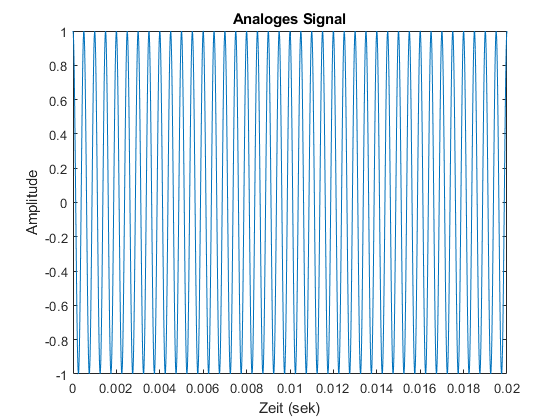

In [1]:
fsim = 80000;
delta_t = (0:1/fsim:0.02)'; 
f0 = 2000;
s  = cos(2*pi*f0*delta_t);

% # grafische Ausgabe # %
figure; 
plot(delta_t,s); 
xlabel('Zeit (sek)'); 
ylabel('Amplitude');
title('Analoges Signal');

### Teilaufgabe b: Spektrum des analogen Signals

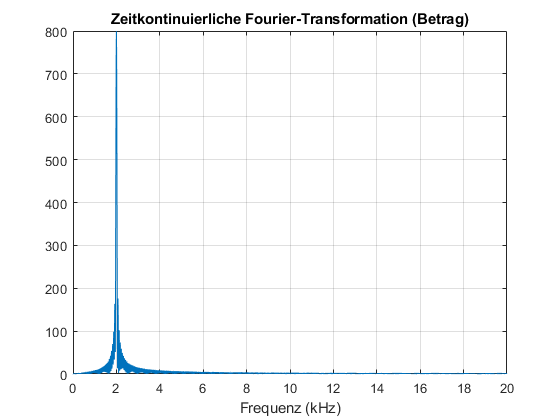

In [2]:
fsim = 80000;
delta_t = (0:1/fsim:0.02)'; 
f0 = 2000;
s  = cos(2*pi*f0*delta_t);

% # grafische Ausgabe # %
figure; 
lafplot(s,1/80000);

## Teilaufgabe c: Abtastung

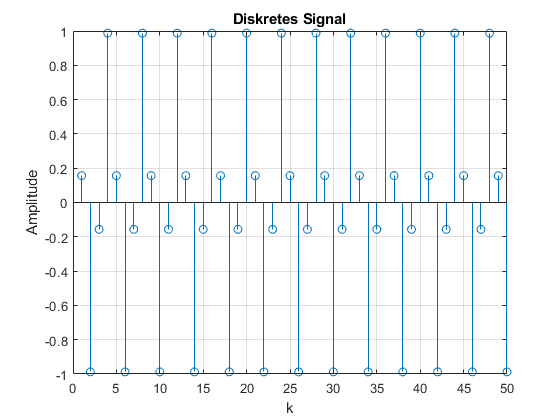

In [3]:
fsim = 80000;
delta_t = (0:1/fsim:0.02)';
f0 = 2000;
s  = cos(2*pi*f0*delta_t);
fa = 8000;
l  = fsim/fa;
index    = (1:l:length(s))-1;
index(1) = [];
sd = s(index);

% # grafische Ausgabe # %
figure; 
stem(sd(1:50)); 
grid; 
xlabel('k'); 
ylabel('Amplitude');
title('Diskretes Signal');

## Teilaufgabe d: Spektrum des zeitdisk. Signals

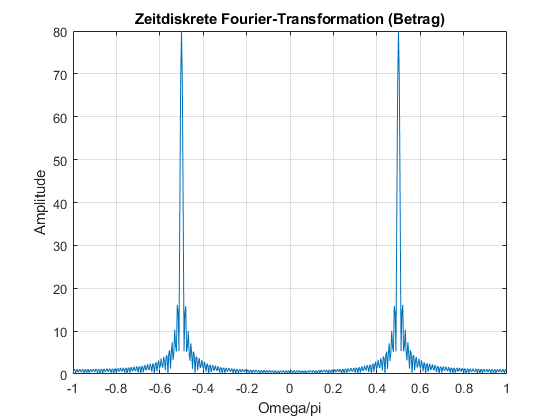

In [4]:
fsim = 80000;
delta_t = (0:1/fsim:0.02)';   
f0 = 2000;
s  = cos(2*pi*f0*delta_t);
fa = 8000;
l  = fsim/fa;
index    = (1:l:length(s))-1;
index(1) = [];
sd = s(index);
[H,W] = ldtft(sd,512);

% # grafische Ausgabe # %
figure; 
plot(W/pi,abs(H)); 
grid; 
xlabel('Omega/pi'); 
ylabel('Amplitude');
title('Zeitdiskrete Fourier-Transformation (Betrag)');

## Teilaufgabe e: Rekonstruktions-TP

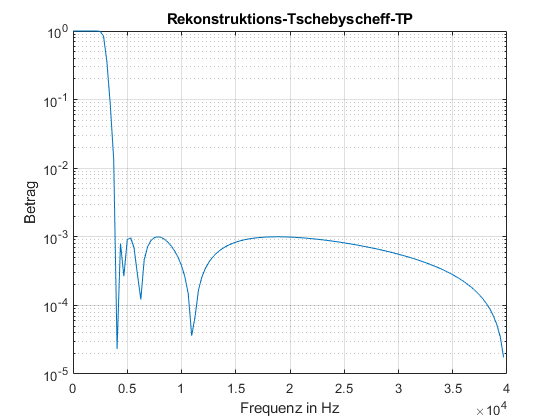

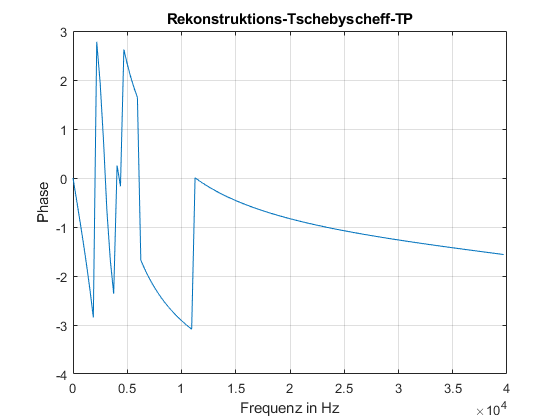

In [5]:
fa    = 8000;
fsim  = 80000;
fcut  = fa/fsim;
[b,a] = cheby2(9,60,fcut);

[H,W] = freqz(b,a,128,fsim);

% # grafische Ausgabe # %
% Frequenzgang
figure; 
semilogy(W,abs(H)); 
grid; 
xlabel('Frequenz in Hz'); 
ylabel('Betrag'); 
title('Rekonstruktions-Tschebyscheff-TP');

% Phasengang
figure; 
plot(W,angle(H));   
grid; 
xlabel('Frequenz in Hz'); 
ylabel('Phase');
title('Rekonstruktions-Tschebyscheff-TP');

## Teilaufgabe f: Analoges Signal

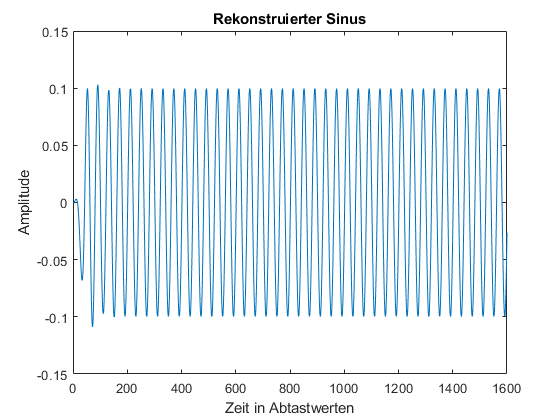

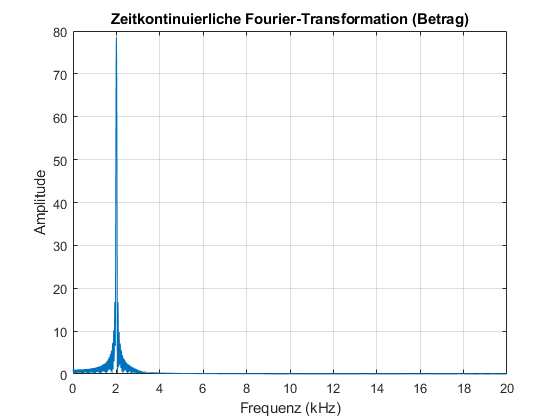

In [6]:
fsim = 80000;             % analoges Signal
delta_t = (0:1/fsim:0.02)';   
f0 = 2000;
s  = cos(2*pi*f0*delta_t);
fa = 8000;                % Abtastung
l  = fsim/fa;
index = (1:l:length(s))-1;
index(1) = [];
sd = s(index);            % diskretes Signal
sa = lzerofill(sd,l);     % Rekonstruktion/Einfuegen von Nullen 
fsim = 80000;             % Tiefpass entwerfen
fcut = fa/fsim;           % siehe Loesung 
[b,a]=cheby2(9,60,fcut);
sr = filter(b,a,sa);      % Rekonstruktion

% # grafische Ausgabe # %
% rekonstruierter Sinus
figure; 
plot(sr); 
title('Rekonstruierter Sinus'); 
xlabel('Zeit in Abtastwerten'); 
ylabel('Amplitude'); 

% Amplitude
figure; 
lafplot(sr,1/80000); 
ylabel('Amplitude');
% #####  EOF  #####